In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

train_df = pd.read_csv(root / "data/processed/train_split.csv")
val_df = pd.read_csv(root / "data/processed/val_split.csv")

# Identify useful sensors using training data only
all_sensors = [f"sensor_{i}" for i in range(1, 22)]

selected_sensors = [
    s for s in all_sensors
    if train_df[s].nunique() > 1
]

# Normalize sensors using ONLY training engines
scaler = StandardScaler()
scaler.fit(train_df[selected_sensors])

print("Selected sensors:", len(selected_sensors))
print("Training engines:", train_df["engine_id"].nunique())
print("Validation engines:", val_df["engine_id"].nunique())


Selected sensors: 15
Training engines: 80
Validation engines: 20


In [2]:

WINDOW = 30

def create_sequences(df, sensors, scaler):
    X, y = [], []

    df = df.sort_values(["engine_id", "cycle"])

    for engine_id, engine in df.groupby("engine_id"):
        # Normalize this engine's sensor readings
        values = scaler.transform(
            engine[sensors]
        ).astype(np.float32)

        rul = engine["RUL"].to_numpy(dtype=np.float32)

        # Sliding window of 30 consecutive cycles
        for end in range(WINDOW - 1, len(engine)):
            start = end - WINDOW + 1

            X.append(values[start:end + 1])
            y.append(rul[end])

    return np.stack(X), np.array(y, dtype=np.float32)


X_train, y_train = create_sequences(
    train_df, selected_sensors, scaler
)

X_val, y_val = create_sequences(
    val_df, selected_sensors, scaler
)

print("=== LSTM DATA PREPARATION ===")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nFirst sequence shape:", X_train[0].shape)
print("First sequence target RUL:", y_train[0])

# Save sequences
np.savez_compressed(
    root / "data/processed/lstm_sequences.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

print("\nLSTM sequences saved!")


=== LSTM DATA PREPARATION ===
X_train: (14241, 30, 15)
y_train: (14241,)
X_val: (3490, 30, 15)
y_val: (3490,)

First sequence shape: (30, 15)
First sequence target RUL: 257.0

LSTM sequences saved!


In [3]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

class RUL_LSTM(nn.Module):
    def __init__(self, input_size=15, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        output, _ = self.lstm(x)

        # Use the last time step
        last_output = output[:, -1, :]

        return self.fc(last_output).squeeze(-1)


model = RUL_LSTM(
    input_size=X_train.shape[2]
).to(device)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters())
)


Using device: cpu
RUL_LSTM(
  (lstm): LSTM(15, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 56129


In [4]:

BATCH_SIZE = 128
RUL_SCALE = 100.0

# Scale RUL targets for more stable training
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train / RUL_SCALE, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

criterion = nn.SmoothL1Loss(beta=0.2)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 112
Validation batches: 28


In [5]:

EPOCHS = 40
PATIENCE = 7

best_val_mae = float("inf")
patience_counter = 0

history = {
    "train_loss": [],
    "val_mae": []
}

model_path = root / "models/lstm_fd001.pt"
model_path.parent.mkdir(parents=True, exist_ok=True)

for epoch in range(EPOCHS):

    # Training
    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        pred = model(xb)
        loss = criterion(pred, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * len(xb)

    train_loss = running_loss / len(train_dataset)

    # Validation
    model.eval()
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)

            pred = model(xb)

            # Convert predictions back to cycles
            pred = pred.cpu().numpy() * RUL_SCALE
            pred = np.maximum(0, pred)

            val_predictions.extend(pred)
            val_targets.extend(yb.numpy())

    val_mae = np.mean(
        np.abs(
            np.array(val_predictions)
            - np.array(val_targets)
        )
    )

    history["train_loss"].append(train_loss)
    history["val_mae"].append(val_mae)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val MAE: {val_mae:.2f}"
    )

    # Save best model based on validation MAE
    if val_mae < best_val_mae:
        best_val_mae = val_mae
        patience_counter = 0

        torch.save({
            "model_state": model.state_dict(),
            "input_size": len(selected_sensors),
            "window": WINDOW,
            "rul_scale": RUL_SCALE,
            "sensor_names": selected_sensors,
            "scaler_mean": scaler.mean_.tolist(),
            "scaler_scale": scaler.scale_.tolist()
        }, model_path)

    else:
        patience_counter += 1

    # Early stopping
    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\n=== TRAINING COMPLETE ===")
print(f"Best Validation MAE: {best_val_mae:.2f} cycles")
print(f"Best model saved to: {model_path}")


Epoch 01/40 | Train Loss: 0.3293 | Val MAE: 21.35
Epoch 02/40 | Train Loss: 0.2029 | Val MAE: 19.58
Epoch 03/40 | Train Loss: 0.1846 | Val MAE: 18.82
Epoch 04/40 | Train Loss: 0.1611 | Val MAE: 19.47
Epoch 05/40 | Train Loss: 0.1489 | Val MAE: 19.96
Epoch 06/40 | Train Loss: 0.1385 | Val MAE: 18.18
Epoch 07/40 | Train Loss: 0.1331 | Val MAE: 18.83
Epoch 08/40 | Train Loss: 0.1284 | Val MAE: 19.48
Epoch 09/40 | Train Loss: 0.1212 | Val MAE: 18.70
Epoch 10/40 | Train Loss: 0.1204 | Val MAE: 19.42
Epoch 11/40 | Train Loss: 0.1159 | Val MAE: 18.53
Epoch 12/40 | Train Loss: 0.1075 | Val MAE: 20.27
Epoch 13/40 | Train Loss: 0.1074 | Val MAE: 20.33

Early stopping triggered.

=== TRAINING COMPLETE ===
Best Validation MAE: 18.18 cycles
Best model saved to: d:\0 Resume Projects\Predictive-Maintenance\models\lstm_fd001.pt


In [6]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the BEST saved LSTM checkpoint (epoch 6)
checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state"])
model.eval()

# Generate predictions
all_preds = []
all_actual = []

with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(device)

        pred = model(xb).cpu().numpy() * RUL_SCALE
        pred = np.maximum(0, pred)

        all_preds.extend(pred)
        all_actual.extend(yb.numpy())

all_preds = np.array(all_preds)
all_actual = np.array(all_actual)

# Overall metrics
mae = mean_absolute_error(all_actual, all_preds)
rmse = np.sqrt(mean_squared_error(all_actual, all_preds))

errors = all_preds - all_actual
over_pct = np.mean(errors > 0) * 100

print("=== LSTM OVERALL PERFORMANCE ===")
print(f"MAE: {mae:.2f} cycles")
print(f"RMSE: {rmse:.2f} cycles")
print(f"Overestimation: {over_pct:.2f}%")

# Near-failure analysis
near_mask = all_actual <= 30
near_errors = errors[near_mask]

near_mae = mean_absolute_error(
    all_actual[near_mask],
    all_preds[near_mask]
)

positive_errors = near_errors[near_errors > 0]

print("\n=== LSTM NEAR-FAILURE PERFORMANCE ===")
print("Samples:", near_mask.sum())
print(f"Near-failure MAE: {near_mae:.2f}")
print(f"Overestimation: {np.mean(near_errors > 0)*100:.2f}%")
print(f"Mean overestimation: {positive_errors.mean() if len(positive_errors) else 0:.2f}")
print(f"Large overestimates (20+): {(near_errors >= 20).sum()}")
print(f"Worst overestimate: {max(0, near_errors.max()):.2f}")


=== LSTM OVERALL PERFORMANCE ===
MAE: 18.18 cycles
RMSE: 25.42 cycles
Overestimation: 53.67%

=== LSTM NEAR-FAILURE PERFORMANCE ===
Samples: 620
Near-failure MAE: 6.11
Overestimation: 85.00%
Mean overestimation: 6.75
Large overestimates (20+): 13
Worst overestimate: 26.24


In [7]:

comparison = pd.DataFrame({
    "Model": ["XGBoost", "LSTM"],
    "Overall MAE": [21.78, mae],
    "Overall RMSE": [30.19, rmse],
    "Overestimation %": [55.27, over_pct],
    "Near Failure MAE": [5.10, near_mae],
    "Large Overestimates (20+)": [
        5, int((near_errors >= 20).sum())
    ]
})

display(comparison.round(2))


,Model,Overall MAE,Overall RMSE,Overestimation %,Near Failure MAE,Large Overestimates (20+)
0,XGBoost,21.78,30.19,55.27,5.10,5
1,LSTM,18.18,25.42,53.67,6.11,13


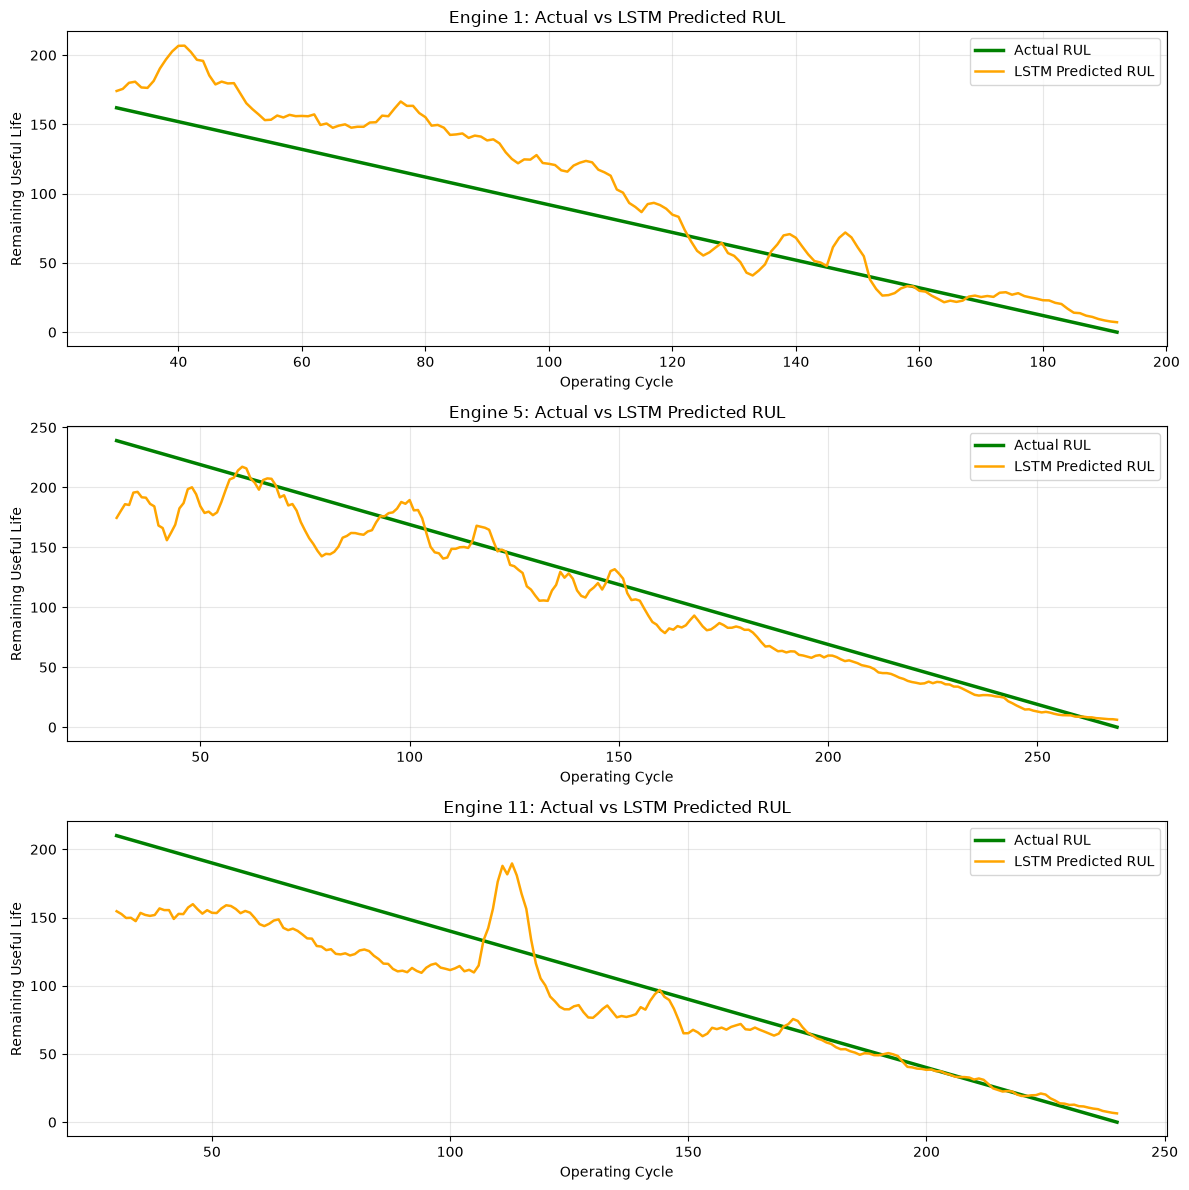

Saved: d:\0 Resume Projects\Predictive-Maintenance\outputs\figures\lstm_vs_actual.png


In [8]:

import matplotlib.pyplot as plt

# Reconstruct engine IDs and cycle numbers
# in exactly the same order as the LSTM sequences.
metadata = pd.concat(
    [
        engine.sort_values("cycle")
        .iloc[WINDOW - 1:][["engine_id", "cycle", "RUL"]]
        for _, engine in val_df.groupby("engine_id")
    ],
    ignore_index=True
)

# Verify prediction alignment
assert len(metadata) == len(all_preds)
assert np.allclose(metadata["RUL"].to_numpy(), all_actual)

metadata["predicted_RUL"] = all_preds

# Same engines used for XGBoost visualizations
engine_ids = [1, 5, 11]

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

for ax, engine_id in zip(axes, engine_ids):
    engine = metadata[
        metadata["engine_id"] == engine_id
    ].sort_values("cycle")

    ax.plot(
        engine["cycle"],
        engine["RUL"],
        label="Actual RUL",
        color="green",
        linewidth=2.5
    )

    ax.plot(
        engine["cycle"],
        engine["predicted_RUL"],
        label="LSTM Predicted RUL",
        color="orange",
        linewidth=1.8
    )

    ax.set_title(
        f"Engine {engine_id}: Actual vs LSTM Predicted RUL"
    )
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Remaining Useful Life")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

output_path = root / "outputs/figures/lstm_vs_actual.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=150)
plt.show()

print("Saved:", output_path)


In [9]:

# Step 20: LSTM safety buffer experiment

results = []

near_mask = all_actual <= 30

for buffer in [0, 3, 5, 10, 15]:

    adjusted = np.maximum(0, all_preds - buffer)

    # Overall metrics
    overall_mae = mean_absolute_error(
        all_actual, adjusted
    )

    overall_rmse = np.sqrt(
        mean_squared_error(all_actual, adjusted)
    )

    # Near-failure metrics
    near_actual = all_actual[near_mask]
    near_pred = adjusted[near_mask]

    errors = near_pred - near_actual

    results.append({
        "Buffer": buffer,
        "Overall MAE": overall_mae,
        "Overall RMSE": overall_rmse,
        "Near Failure MAE": mean_absolute_error(
            near_actual, near_pred
        ),
        "Near Overestimation %": (errors > 0).mean() * 100,
        "Large Overestimates (20+)": (errors >= 20).sum(),
        "Worst Overestimate": max(0, errors.max())
    })

buffer_results = pd.DataFrame(results)

print("=== LSTM BUFFER EXPERIMENT ===")
display(buffer_results.round(2))


=== LSTM BUFFER EXPERIMENT ===


,Buffer,Overall MAE,Overall RMSE,Near Failure MAE,Near Overestimation %,Large Overestimates (20+),Worst Overestimate
0,0,18.18,25.42,6.11,85.00,13,26.24
1,3,18.20,25.75,4.50,65.97,3,23.24
2,5,18.49,26.16,4.17,49.84,2,21.24
3,10,20.11,27.79,5.80,17.26,0,16.24
4,15,22.40,30.09,8.18,6.77,0,11.24
